# Descenso de gradiente estocástico (SGD)

El descenso de gradiente del notebook anterior usa **todos los datos** para calcular cada paso. Con diez entregas da lo mismo. Con diez millones, cada paso cuesta recorrer el conjunto completo, y para entrenar hacen falta miles de pasos.

El descenso de gradiente estocástico (SGD, *stochastic gradient descent*) parte de una observación simple: para saber hacia dónde bajar no hace falta el gradiente exacto, basta una **estimación** hecha con unos pocos ejemplos elegidos al azar. Es el algoritmo con el que se entrena prácticamente toda red neuronal.

**Contenido**

1. El costo de un paso
2. Estimar el gradiente con una muestra
3. Batch, estocástico y mini-batch
4. Las tres variantes en acción
5. El ruido no desaparece solo
6. Bajar la tasa de aprendizaje con el tiempo
7. SGD en PyTorch: `Dataset` y `DataLoader`
8. Resumen y ejercicios

In [1]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 1. El costo de un paso

La pérdida es un promedio sobre los $N$ ejemplos:

$$L(\theta) = \frac{1}{N} \sum_{i=1}^{N} \ell_i(\theta)$$

donde $\theta$ junta todos los parámetros y $\ell_i$ es el error en el ejemplo $i$. Como la derivada de una suma es la suma de las derivadas, el gradiente también es un promedio:

$$\nabla L(\theta) = \frac{1}{N} \sum_{i=1}^{N} \nabla \ell_i(\theta)$$

Calcularlo exige pasar por los $N$ ejemplos. Ese es el costo de **un solo paso** del descenso de gradiente clásico.

Para experimentar usamos un conjunto más grande que el de los notebooks anteriores: 200 entregas generadas con la regla $\text{tiempo} = 5 \cdot \text{distancia} + 2$ más ruido. La entrada va estandarizada, por lo visto en el notebook anterior.

In [2]:
N = 200

distancias = torch.rand(N) * 5.5 + 0.5                       # entre 0.5 y 6 millas
tiempos = 5 * distancias + 2 + torch.randn(N) * 1.5          # ruido de 1.5 minutos

x = (distancias - distancias.mean()) / distancias.std()      # entrada estandarizada
y = tiempos

# Solución exacta, como referencia para medir qué tan cerca llega cada método
A = torch.stack([x, torch.ones(N)], dim=1)
optimo = torch.linalg.lstsq(A, y.unsqueeze(1)).solution.squeeze()
print(f"Parámetros óptimos: w = {optimo[0]:.3f}, b = {optimo[1]:.3f}")

Parámetros óptimos: w = 7.879, b = 18.081


## 2. Estimar el gradiente con una muestra

En lugar de promediar sobre los $N$ ejemplos, tomamos un **lote** (*batch*) $\mathcal{B}$ de $B$ ejemplos al azar y promediamos solo sobre ellos:

$$g_{\mathcal{B}}(\theta) = \frac{1}{B} \sum_{i \in \mathcal{B}} \nabla \ell_i(\theta)$$

Es la misma idea que una encuesta: para estimar el promedio de una población no se le pregunta a todo el mundo, se le pregunta a una muestra al azar. Esta estimación tiene dos propiedades que explican todo lo que sigue.

**No tiene sesgo.** Si los ejemplos se eligen al azar de manera uniforme, el valor esperado del gradiente del lote es el gradiente completo:

$$\mathbb{E}\left[ g_{\mathcal{B}}(\theta) \right] = \nabla L(\theta)$$

En promedio apunta en la dirección correcta. Cada estimación individual se desvía, pero las desviaciones no tienen una dirección preferida.

**Su ruido baja al aumentar el lote.** La varianza de un promedio de $B$ muestras independientes es la varianza de una muestra dividida por $B$. La desviación estándar cae entonces como $1 / \sqrt{B}$: para reducir el ruido a la mitad hay que cuadruplicar el lote.

Lo comprobamos. Fijamos un punto $(w, b)$, calculamos el gradiente de cada ejemplo por separado con las fórmulas del notebook anterior, y miramos cómo se distribuye la estimación de $\partial L / \partial w$ para distintos tamaños de lote.

lote de  1:  media de las estimaciones = -15.493   desviación = 40.179
lote de  8:  media de las estimaciones = -15.436   desviación = 14.148


lote de 64:  media de las estimaciones = -15.657   desviación =  5.013

gradiente completo (los 200 ejemplos) = -15.679


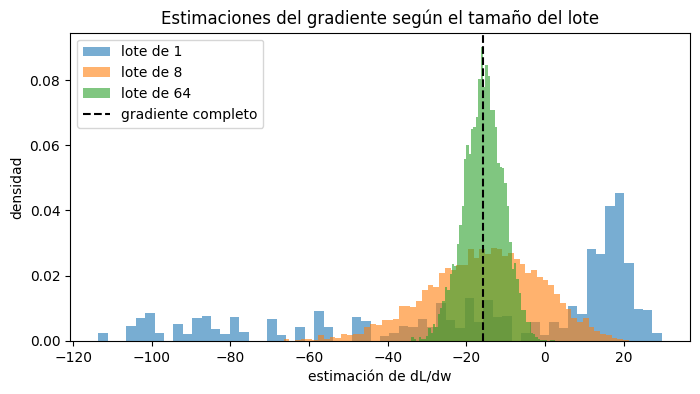

In [3]:
w, b = 0.0, 0.0

error = w * x + b - y
grad_w_por_ejemplo = 2 * error * x              # un valor por cada ejemplo
grad_w_completo = grad_w_por_ejemplo.mean()     # el gradiente exacto

fig, eje = plt.subplots(figsize=(8, 4))

for B in [1, 8, 64]:
    indices = torch.randint(0, N, (5000, B))                # 5000 lotes al azar de tamaño B
    estimaciones = grad_w_por_ejemplo[indices].mean(dim=1)
    eje.hist(estimaciones, bins=60, alpha=0.6, density=True, label=f"lote de {B}")
    print(f"lote de {B:2d}:  media de las estimaciones = {estimaciones.mean():7.3f}   "
          f"desviación = {estimaciones.std():6.3f}")

print(f"\ngradiente completo (los {N} ejemplos) = {grad_w_completo:7.3f}")

eje.axvline(grad_w_completo, color="black", linestyle="--", label="gradiente completo")
eje.set_xlabel("estimación de dL/dw")
eje.set_ylabel("densidad")
eje.set_title("Estimaciones del gradiente según el tamaño del lote")
eje.legend()
plt.show()

Las tres distribuciones están centradas en el gradiente completo (sin sesgo). Al multiplicar el tamaño del lote por 8, la desviación se divide aproximadamente por $\sqrt{8} \approx 2.8$. (El experimento sortea los ejemplos de cada lote con reemplazo, que es el caso que describe la fórmula. En el entrenamiento los lotes se arman sin repetir ejemplos, y el ruido es incluso algo menor.)

Con un solo ejemplo la estimación es muy ruidosa, pero cuesta 200 veces menos que el gradiente completo. Ese es el intercambio que hace SGD: **muchos pasos baratos e imprecisos en lugar de pocos pasos caros y exactos**.

## 3. Batch, estocástico y mini-batch

Según cuántos ejemplos se usen por paso hay tres variantes. El algoritmo es el mismo, $\theta \leftarrow \theta - \eta \, g$, y solo cambia con qué se calcula $g$.

| Variante | Ejemplos por paso | Pasos por época | Gradiente |
|---|---|---|---|
| **Batch** (descenso de gradiente clásico) | todos ($N$) | 1 | exacto |
| **Estocástico** (SGD puro) | 1 | $N$ | muy ruidoso |
| **Mini-batch** | $B$ (típicamente 16 a 512) | $N / B$, redondeado hacia arriba | algo ruidoso |

Vocabulario que se usa todo el tiempo:

- **Iteración** o **paso**: una actualización de los parámetros.
- **Época**: una pasada completa por los datos. En una época todas las variantes procesan los mismos $N$ ejemplos; lo que cambia es cuántas actualizaciones hacen con ellos.

En la práctica se usa casi siempre **mini-batch**, y cuando alguien dice "SGD" suele referirse a eso. Tiene menos ruido que el caso de un ejemplo y además aprovecha que el hardware procesa un lote completo en paralelo casi al mismo costo que un ejemplo.

Los lotes se arman así: al inicio de cada época se **desordenan** los datos y luego se recorren en trozos de tamaño $B$. Así cada ejemplo se usa exactamente una vez por época, y el orden cambia de una época a otra.

In [4]:
def entrenar(x, y, tam_lote, lr, epocas, semilla=0):
    """Descenso de gradiente con lotes de tamaño tam_lote. Devuelve la trayectoria de (w, b)."""
    generador = torch.Generator().manual_seed(semilla)
    w = torch.tensor(0.0, requires_grad=True)
    b = torch.tensor(0.0, requires_grad=True)
    trayectoria = [(w.item(), b.item())]
    n = len(x)
    paso = 0

    for epoca in range(epocas):
        orden = torch.randperm(n, generator=generador)          # desordenar en cada época

        for inicio in range(0, n, tam_lote):
            lote = orden[inicio:inicio + tam_lote]              # índices de este lote

            perdida = ((w * x[lote] + b - y[lote]) ** 2).mean() # pérdida solo en el lote
            perdida.backward()

            tasa = lr(paso) if callable(lr) else lr             # admite una tasa fija o una función del paso
            with torch.no_grad():
                w -= tasa * w.grad
                b -= tasa * b.grad
            w.grad.zero_()
            b.grad.zero_()

            trayectoria.append((w.item(), b.item()))
            paso += 1

    return torch.tensor(trayectoria)

La única diferencia con el descenso de gradiente del notebook anterior es `x[lote]` y `y[lote]`: la pérdida se calcula sobre un trozo de los datos. Con `tam_lote = N` se recupera el método clásico.

## 4. Las tres variantes en acción

Entrenamos durante 5 épocas con cada variante, con la misma tasa de aprendizaje, y dibujamos el camino sobre la superficie de pérdida.

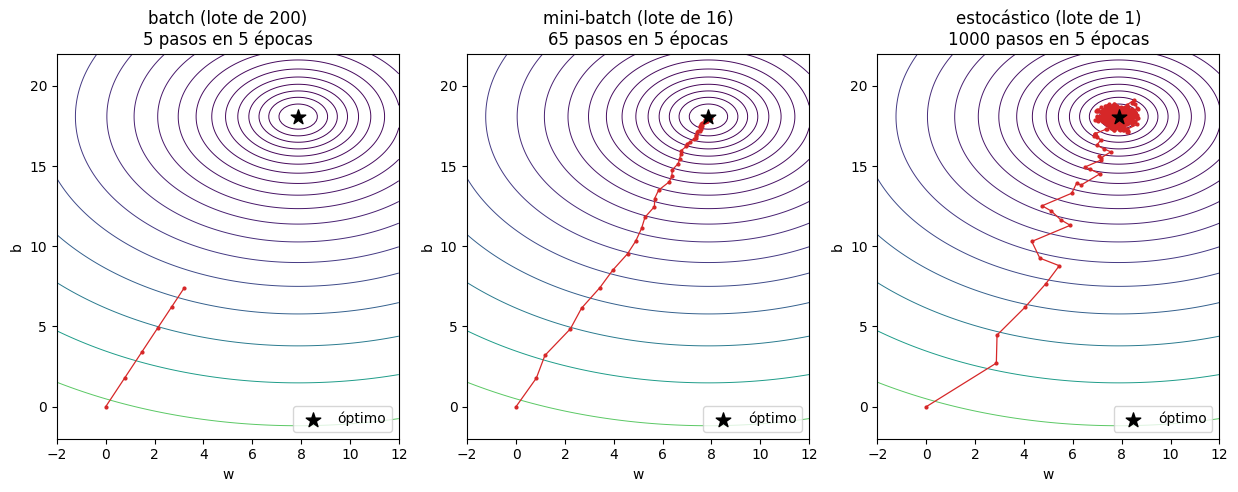

batch (lote de 200)        pérdida tras 5 épocas =  137.433
mini-batch (lote de 16)    pérdida tras 5 épocas =    1.780
estocástico (lote de 1)    pérdida tras 5 épocas =    1.811


In [5]:
def perdida_total(w, b):
    return ((w * x + b - y) ** 2).mean()


variantes = {
    f"batch (lote de {N})": entrenar(x, y, tam_lote=N, lr=0.05, epocas=5),
    "mini-batch (lote de 16)": entrenar(x, y, tam_lote=16, lr=0.05, epocas=5),
    "estocástico (lote de 1)": entrenar(x, y, tam_lote=1, lr=0.05, epocas=5),
}

# Superficie de pérdida sobre una grilla de (w, b)
ws = torch.linspace(-2, 12, 150)
bs = torch.linspace(-2, 22, 150)
W, B_ = torch.meshgrid(ws, bs, indexing="xy")
L = ((W.unsqueeze(-1) * x + B_.unsqueeze(-1) - y) ** 2).mean(dim=-1)
niveles = torch.logspace(torch.log10(L.min()).item(), torch.log10(L.max()).item(), 20).tolist()

fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for eje, (nombre, tray) in zip(ejes, variantes.items()):
    eje.contour(W, B_, L, levels=niveles, cmap="viridis", linewidths=0.7)
    eje.plot(tray[:, 0], tray[:, 1], linewidth=0.9, marker="o", markersize=2, color="tab:red")
    eje.scatter(*optimo, color="black", marker="*", s=120, zorder=3, label="óptimo")
    eje.set_title(f"{nombre}\n{len(tray) - 1} pasos en 5 épocas")
    eje.set_xlabel("w")
    eje.set_ylabel("b")
    eje.legend(loc="lower right")
plt.show()

for nombre, tray in variantes.items():
    print(f"{nombre:26s} pérdida tras 5 épocas = {perdida_total(tray[-1, 0], tray[-1, 1]).item():8.3f}")

Las tres variantes vieron los mismos datos la misma cantidad de veces (5 épocas), pero:

- **Batch** dio solo 5 pasos. Cada uno es exacto y el camino es limpio, pero quedó lejos del óptimo.
- **Mini-batch** dio 13 pasos por época. El camino tiembla un poco y llega a la zona del óptimo.
- **Estocástico** dio 200 pasos por época. Llega rápido a la zona del óptimo y después se queda dando vueltas alrededor.

Con el mismo presupuesto de cómputo, medido en ejemplos procesados, las variantes con lotes pequeños avanzan mucho más. Ese es el motivo práctico para usar SGD.

## 5. El ruido no desaparece solo

En el gráfico anterior el caso estocástico no se detiene en el óptimo: lo ronda. La razón es que **en el óptimo el gradiente completo es cero, pero el gradiente de cada lote no**. Cada lote "opina" que hay que moverse un poco en alguna dirección, y como esas opiniones no se anulan dentro de un mismo paso, los parámetros siguen saltando.

El tamaño de esos saltos es proporcional a la tasa de aprendizaje. Lo medimos graficando la distancia al óptimo en cada paso, con lotes de 1 y dos tasas distintas:

lr = 0.05   distancia media al óptimo en los últimos 1000 pasos: 0.364


lr = 0.005  distancia media al óptimo en los últimos 1000 pasos: 0.070


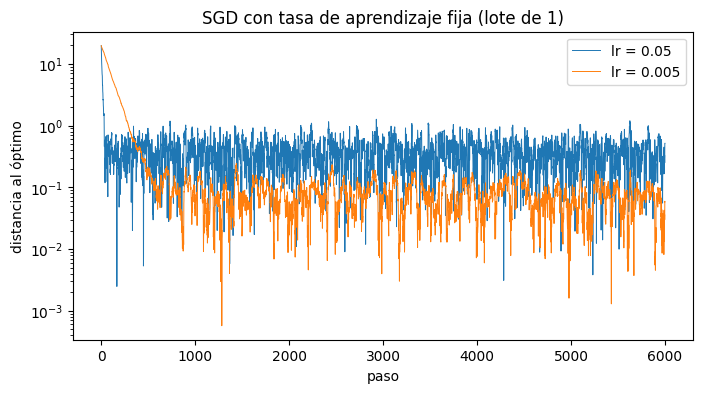

In [6]:
def distancia_al_optimo(tray):
    return (tray - optimo).norm(dim=1)


fig, eje = plt.subplots(figsize=(8, 4))
for lr in [0.05, 0.005]:
    tray = entrenar(x, y, tam_lote=1, lr=lr, epocas=30)
    dist = distancia_al_optimo(tray)
    eje.plot(dist, linewidth=0.7, label=f"lr = {lr}")
    print(f"lr = {lr:<6} distancia media al óptimo en los últimos 1000 pasos: {dist[-1000:].mean():.3f}")

eje.set_yscale("log")
eje.set_xlabel("paso")
eje.set_ylabel("distancia al óptimo")
eje.set_title("SGD con tasa de aprendizaje fija (lote de 1)")
eje.legend()
plt.show()

Con tasa fija, SGD tiene dos fases:

1. **Acercamiento.** Lejos del óptimo el gradiente verdadero es grande comparado con el ruido, y la distancia baja con rapidez.
2. **Meseta.** Cerca del óptimo domina el ruido y la distancia deja de bajar: queda oscilando en torno a un nivel.

La tasa grande llega antes pero se estanca más arriba. La tasa pequeña demora más y termina más cerca. Con tasa fija hay que elegir entre velocidad y precisión.

## 6. Bajar la tasa de aprendizaje con el tiempo

La salida es no elegir: partir con una tasa grande para avanzar rápido e ir **reduciéndola** para que el ruido se apague. A esa regla se le llama *schedule* o programación de la tasa de aprendizaje.

La teoría dice cuánto hay que bajarla. El resultado clásico es que, en problemas convexos como este y con ruido de varianza acotada, SGD converge al óptimo si la secuencia de tasas $\eta_t$ cumple las **condiciones de Robbins-Monro**:

$$\sum_{t=1}^{\infty} \eta_t = \infty \qquad\qquad \sum_{t=1}^{\infty} \eta_t^2 < \infty$$

- La primera dice que las tasas no pueden achicarse demasiado rápido: la suma de todos los pasos tiene que poder cubrir cualquier distancia, por lejos que se parta.
- La segunda dice que sí tienen que achicarse lo suficiente para que el ruido acumulado sea finito.

Una secuencia que cumple ambas es $\eta_t = \dfrac{\eta_0}{1 + t / \tau}$, que decae como $1/t$. La probamos contra las dos tasas fijas:

lr fija = 0.05              distancia media en los últimos 1000 pasos: 0.3642


lr fija = 0.005             distancia media en los últimos 1000 pasos: 0.0703


lr decreciente desde 0.05   distancia media en los últimos 1000 pasos: 0.0275


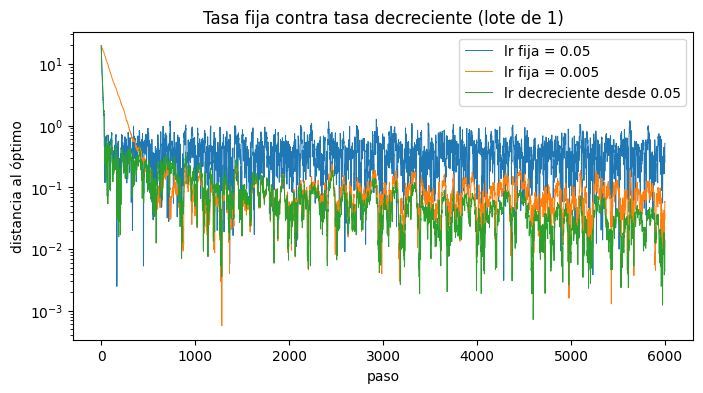

In [7]:
def tasa_decreciente(paso, lr_inicial=0.05, tau=200):
    return lr_inicial / (1 + paso / tau)


configuraciones = {
    "lr fija = 0.05": 0.05,
    "lr fija = 0.005": 0.005,
    "lr decreciente desde 0.05": tasa_decreciente,
}

fig, eje = plt.subplots(figsize=(8, 4))
for nombre, lr in configuraciones.items():
    dist = distancia_al_optimo(entrenar(x, y, tam_lote=1, lr=lr, epocas=30))
    eje.plot(dist, linewidth=0.7, label=nombre)
    print(f"{nombre:27s} distancia media en los últimos 1000 pasos: {dist[-1000:].mean():.4f}")

eje.set_yscale("log")
eje.set_xlabel("paso")
eje.set_ylabel("distancia al óptimo")
eje.set_title("Tasa fija contra tasa decreciente (lote de 1)")
eje.legend()
plt.show()

La tasa decreciente arranca tan rápido como la tasa grande y termina más cerca del óptimo que cualquiera de las dos fijas, porque el ruido se va apagando a medida que la tasa baja.

PyTorch trae estas reglas en `torch.optim.lr_scheduler` (`StepLR`, `ExponentialLR`, `CosineAnnealingLR` y otras). Se usan llamando a `scheduler.step()` después de `optimizador.step()`.

La otra forma de reducir el ruido es agrandar el lote, como se vio en la sección 2. Subir el tamaño del lote y bajar la tasa de aprendizaje tienen efectos parecidos sobre el ruido.

## 7. SGD en PyTorch: `Dataset` y `DataLoader`

Hasta aquí armamos los lotes a mano. PyTorch tiene dos clases que se encargan de eso:

- **`Dataset`**: representa los datos y sabe entregar el ejemplo número $i$. `TensorDataset` es la versión más simple: envuelve tensores que ya están en memoria.
- **`DataLoader`**: recorre un `Dataset` entregando lotes. Con `shuffle=True` desordena los datos al inicio de cada época, igual que nuestro `torch.randperm`.

In [8]:
X = x.unsqueeze(1)            # forma [200, 1], como espera nn.Linear
Y = y.unsqueeze(1)

datos = TensorDataset(X, Y)
cargador = DataLoader(datos, batch_size=16, shuffle=True)

print("ejemplos en el dataset:", len(datos))
print("lotes por época       :", len(cargador))

lote_x, lote_y = next(iter(cargador))
print("forma de un lote      :", lote_x.shape, lote_y.shape)

ejemplos en el dataset: 200
lotes por época       : 13
forma de un lote      : torch.Size([16, 1]) torch.Size([16, 1])


200 ejemplos en lotes de 16 dan 13 lotes: doce completos y uno final con los 8 ejemplos que sobran.

El ciclo de entrenamiento gana un segundo `for`: el de afuera recorre épocas y el de adentro recorre los lotes de cada época. Los cinco pasos de siempre quedan dentro del ciclo interior.

In [9]:
torch.manual_seed(42)

modelo = nn.Linear(1, 1)
criterio = nn.MSELoss()
optimizador = torch.optim.SGD(modelo.parameters(), lr=0.05)

for epoca in range(10):
    suma = 0.0

    for lote_x, lote_y in cargador:                 # un paso por cada lote
        perdida = criterio(modelo(lote_x), lote_y)

        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()

        suma += perdida.item() * len(lote_x)        # se pondera por el tamaño del lote

    print(f"época {epoca}   pérdida media = {suma / len(datos):8.3f}")

print(f"\nAprendido: w = {modelo.weight.item():.3f}, b = {modelo.bias.item():.3f}")
print(f"Óptimo   : w = {optimo[0]:.3f}, b = {optimo[1]:.3f}")

época 0   pérdida media =  138.375
época 1   pérdida media =   10.521
época 2   pérdida media =    2.271
época 3   pérdida media =    1.815
época 4   pérdida media =    1.799
época 5   pérdida media =    1.801
época 6   pérdida media =    1.796
época 7   pérdida media =    1.800
época 8   pérdida media =    1.792
época 9   pérdida media =    1.809

Aprendido: w = 7.902, b = 18.024
Óptimo   : w = 7.879, b = 18.081


Dos aclaraciones sobre este código.

**`torch.optim.SGD` no elige los lotes.** El optimizador solo aplica $\theta \leftarrow \theta - \eta \, g$ con el gradiente que encuentre en `.grad`. Lo *estocástico* viene de cómo le entregas los datos: si en cada paso le pasas un lote al azar, es SGD; si le pasas todos los datos, como en el módulo 01, es descenso de gradiente clásico con el mismo optimizador.

**La pérdida de cada lote es ruidosa.** Depende de qué ejemplos tocaron. Por eso se informa el promedio de la época, ponderando cada lote por su tamaño porque el último puede ser más chico.

Los parámetros aprendidos quedan cerca del óptimo y no exactamente en él, como anticipa la sección 5: la tasa es fija y el ruido no se apaga.

## 8. Resumen

- El gradiente completo es un promedio sobre todos los datos, y calcularlo en cada paso es caro.
- SGD lo reemplaza por el gradiente de un **lote al azar**: una estimación sin sesgo cuyo ruido cae como $1 / \sqrt{B}$.
- Con el mismo cómputo, los lotes pequeños dan muchos más pasos y avanzan más. Por eso **mini-batch** es el estándar.
- Con tasa de aprendizaje fija, SGD llega rápido a la zona del óptimo y se queda oscilando a una distancia que crece con la tasa.
- Para acercarse más hay que **reducir la tasa** con el tiempo (las condiciones de Robbins-Monro dicen cuánto) o agrandar el lote.
- En PyTorch, `DataLoader` arma los lotes y `torch.optim.SGD` aplica la actualización. Lo estocástico está en los datos que le pasas.

El ruido de SGD no es solo un costo. En funciones con varios mínimos o puntos silla ayuda a no quedarse atrapado, como se ve en `03-optimalidad`.

## Ejercicios

1. En la sección 2, agrega un lote de tamaño 256 al experimento. ¿Qué desviación esperas según la regla $1/\sqrt{B}$? Compárala con la medida.
2. En la sección 4, entrena la variante batch durante 200 épocas. Son 200 pasos, los mismos que da el caso estocástico en una sola época. ¿Quién queda más cerca del óptimo? ¿Cuántos ejemplos procesó cada uno?
3. En la sección 5, repite el experimento con `tam_lote=16`. ¿Cómo cambia la altura de la meseta?
4. En la sección 6, cambia `tau` a 20 y a 5000. ¿Qué pasa en cada extremo y por qué?
5. En la sección 7, cambia `shuffle=True` por `shuffle=False` y ordena antes los datos por distancia. ¿Cómo afecta al entrenamiento? ¿Por qué importa desordenar?
6. Agrega un `torch.optim.lr_scheduler.ExponentialLR(optimizador, gamma=0.8)` al ciclo de la sección 7, llamando a `scheduler.step()` al final de cada época. Compara los parámetros finales con el óptimo.